In [1]:
import numpy as np
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

### Generate and Prepare Data

In [2]:
def generate_examples(num_examples=1000, dim=100, var=1, means=None, priors=None):
    num_a_1 = 0
    num_a_0 = 0
    a_1_prob = priors['a_1']
    for i in range(num_examples):
        if np.random.uniform(0,1) < a_1_prob:
            num_a_1 += 1
        else:
            num_a_0 += 1
    num_y_1_a_1 = 0
    num_y_0_a_1 = 0
    y_1_a_1_prob = priors['y_1_a_1']
    for i in range(num_a_1):
        if np.random.uniform(0,1) < y_1_a_1_prob:
            num_y_1_a_1 += 1
        else:
            num_y_0_a_1 += 1
    num_y_1_a_0 = 0
    num_y_0_a_0 = 0
    y_1_a_0_prob = priors['y_1_a_0']
    for i in range(num_a_0):
        if np.random.uniform(0,1) < y_1_a_0_prob:
            num_y_1_a_0 += 1
        else:
            num_y_0_a_0 += 1
    covar = var*np.eye(dim) # Spherical gaussian for now
    if means is None:
        if dim == 2:
            mu_0_0 = np.asarray([1,1])
            mu_1_0 = np.asarray([-1,1])
            mu_0_1 = np.asarray([5,-2])
            mu_1_1 = np.asarray([-5,-2])
        else:
            mu_0_0 = [np.random.uniform(0,1) for i in range(dim)]
            mu_1_0 = [np.random.uniform(0,1) for i in range(dim)]
            mu_0_1 = [np.random.uniform(0,1) for i in range(dim)]
            mu_1_1 = [np.random.uniform(0,1) for i in range(dim)]
    else:
        mu_0_0 = means[0]
        mu_0_1 = means[1]
        mu_1_0 = means[2]
        mu_1_1 = means[3]
    # Samples
    samples_0_0 = np.random.multivariate_normal(mu_0_0, covar, num_y_0_a_0)
    samples_0_1 = np.random.multivariate_normal(mu_0_1, covar, num_y_0_a_1)
    samples_1_0 = np.random.multivariate_normal(mu_1_0, covar, num_y_1_a_0)
    samples_1_1 = np.random.multivariate_normal(mu_1_1, covar, num_y_1_a_1)
    sensitive = np.asarray([0]*len(samples_0_0) + [1]*len(samples_0_1) + [0]*len(samples_1_0) + [1]*len(samples_1_1))
    label = np.asarray([0]*len(samples_0_0) + [0]*len(samples_0_1) + [1]*len(samples_1_0) + [1]*len(samples_1_1))
    mean_dict = {
        '00': mu_0_0,
        '01': mu_0_1,
        '10': mu_1_0,
        '11': mu_1_1
    }
    covar_dict = {
        '00': covar,
        '01': covar,
        '10': covar,
        '11': covar
    }
    return mean_dict, covar_dict, np.vstack((samples_0_0, samples_0_1, samples_1_0, samples_1_1)), sensitive, label

In [3]:
def get_eta(x, mu, covar, priors, a, eps=0.001):
    density_y1 = multivariate_normal.pdf(x, mu[f'1{a}'], covar[f'1{a}'])
    numerator = density_y1 * priors[f'y_1_a_{a}']

    density_y0 = multivariate_normal.pdf(x, mu[f'0{a}'], covar[f'0{a}'])
    denominator = numerator + density_y0 * priors[f'y_0_a_{a}']
    return numerator/denominator

In [4]:
priors = {
    'a_1': 0.7,
    'a_0': 0.3,
    'y_1_a_1': 0.7,
    'y_0_a_1': 0.3,
    'y_1_a_0': 0.4,
    'y_0_a_0': 0.6
}

dim = 2
var=2
train_samples = 5000
val_samples = 5000

means, covars, samples, sensitive, labels = generate_examples(num_examples=train_samples, dim=dim, var=var, priors=priors)
_,_, est_samples, est_sensitive, est_labels = generate_examples(num_examples=val_samples, dim=dim, var=var, means=list(means.values()), priors=priors)
print(samples.shape, sensitive.shape, labels.shape)
print(est_samples.shape, est_sensitive.shape, est_labels.shape)

(5000, 2) (5000,) (5000,)
(5000, 2) (5000,) (5000,)


In [5]:
# We will now have a data of form (c,a,y), (c_est, a_est, y_est) and this is where our story begins
soft_labels = []
for i in range(samples.shape[0]):
    temp_score = get_eta(samples[i], means, covars, priors, sensitive[i])  
    # if labels[i] == 0:
    #     temp_score = 1 - temp_score
    soft_labels.append(temp_score)
est_soft_labels = []
for i in range(est_samples.shape[0]):
    temp_score = get_eta(est_samples[i], means, covars, priors, est_sensitive[i])  
    # if est_labels[i] == 0:
    #     temp_score = 1 - temp_score
    est_soft_labels.append(temp_score)

In [6]:
# Plot soft labels as a histogram
soft_labels = np.asarray(soft_labels)
est_soft_labels = np.asarray(est_soft_labels)
sensitive = np.asarray(sensitive)
est_sensitive = np.asarray(est_sensitive)
labels = np.asarray(labels)
est_labels = np.asarray(est_labels)
# Plot color coded histogram (group 0: red, group 1: blue)
plt.figure(figsize=(10, 5))
#plt.hist(soft_labels[np.where((labels == 0) & (sensitive == 0))[0]], bins=50, alpha=0.5, color='red', label='Group 0, Label 0')
#plt.hist(soft_labels[np.where((labels == 1) & (sensitive == 0))[0]], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1')
#plt.hist(soft_labels[np.where((labels == 0) & (sensitive == 1))[0]], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0')
#plt.hist(soft_labels[np.where((labels == 1) & (sensitive == 1))[0]], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1')


plt.figure(figsize=(10, 5))
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 0))[0]], bins=50, alpha=0.5, color='red', label='Group 0, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 0))[0]], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1', density=True)
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 1))[0]], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 1))[0]], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1', density=True)

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

In [7]:
# # plot the distribution
# def plot_distribution(samples, sensitive, labels, means, covars):
#     plt.figure(figsize=(10, 6))
#     color_00 = 'blue'
#     color_01 = 'orange'
#     color_10 = 'green'
#     color_11 = 'red'

#     indices_00 = np.where((labels == 0) & (sensitive == 0))[0]
#     indices_01 = np.where((labels == 0) & (sensitive == 1))[0]
#     indices_10 = np.where((labels == 1) & (sensitive == 0))[0]
#     indices_11 = np.where((labels == 1) & (sensitive == 1))[0]

#     plt.scatter(samples[indices_00, 0], samples[indices_00, 1], color=color_00, alpha=0.5, label='Label=0, Sensitive=0')
#     plt.scatter(samples[indices_01, 0], samples[indices_01, 1], color=color_01, alpha=0.5, label='Label=0, Sensitive=1')
#     plt.scatter(samples[indices_10, 0], samples[indices_10, 1], color=color_10, alpha=0.5, label='Label=1, Sensitive=0')
#     plt.scatter(samples[indices_11, 0], samples[indices_11, 1], color=color_11, alpha=0.5, label='Label=1, Sensitive=1')
#     plt.scatter(means['00'][0], means['00'][1], color=color_00, marker='x', s=100, label='Mean 00')
#     plt.scatter(means['01'][0], means['01'][1], color=color_01, marker='x', s=100, label='Mean 01')
#     plt.scatter(means['10'][0], means['10'][1], color=color_10, marker='x', s=100, label='Mean 10')
#     plt.scatter(means['11'][0], means['11'][1], color=color_11, marker='x', s=100, label='Mean 11')
#     plt.title('Distribution of Samples with Sensitive Attributes and Labels')
#     plt.xlabel('Feature 1')
#     plt.ylabel('Feature 2')
#     plt.legend()
#     plt.grid()
#     plt.show()
# plot_distribution(samples, sensitive, labels, means, covars)

### Baselines

In [8]:
import sys
import os
import pandas as pd
sys.path.append(os.path.join(os.getcwd(), 'FairPareto'))

from FairPareto.fairpareto.core import FairParetoClassifier

# Load your data (X should include the sensitive attribute column)
# Modified the class to work with custom soft labels
#feature_group = np.column_stack((samples, sensitive))
data_df = pd.DataFrame(samples)
data_df['sensitive'] = sensitive
from sklearn.ensemble import RandomForestClassifier

clf = FairParetoClassifier(soft=[
    soft_labels[np.where(sensitive == 0)[0]],
    soft_labels[np.where(sensitive == 1)[0]]
], sensitive_column='sensitive')
clf.fit(data_df, labels)

pareto_front = clf.get_pareto_front()
print(pareto_front)

ModuleNotFoundError: No module named 'fairgbm'

In [8]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, TruePositiveRateParity
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
# Train Exp-grad
# Repeat for DP
eps_cls = {}
# for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]):
#     #constraint = DemographicParity()
#     constraint = TruePositiveRateParity()
#     mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
#     mitigator.fit(samples, labels, sensitive_features=sensitive)
#     eps_cls[eps] = mitigator
for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]):
    #constraint = DemographicParity()
    constraint = TruePositiveRateParity()
    mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
    mitigator.fit(samples, labels, sensitive_features=sensitive)
    eps_cls[eps] = mitigator

100%|██████████| 7/7 [00:18<00:00,  2.62s/it]


### Algorithm

In [20]:
from utils import soft_estimator, test_monotonicity

estimated_priors = soft_estimator(soft_labels, sensitive)
D_est = {
    'C': np.asarray(est_soft_labels),
    'A': est_sensitive
}
D = {
    'C': np.asarray(soft_labels),
    'A': sensitive
}

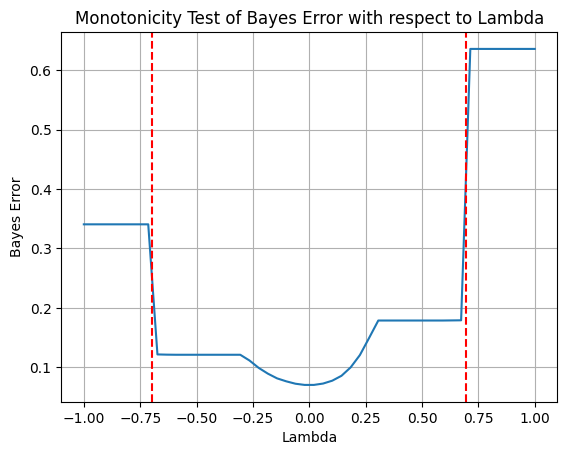

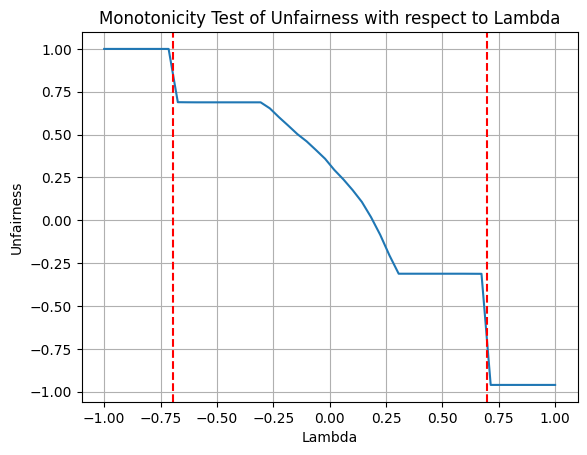

In [22]:
test_monotonicity(estimated_priors, D_est, 'dp')

In [23]:
from utils import return_tradeoff

true_tradeoff, true_bayes, true_unf = return_tradeoff(D_est, priors, constraint='eop', delta=0.001, eps=0.0001)

0.07439909710016324 0.3176158129472504 0.48999999999999994
lambda: 0.24499999999999997, Alpha_0: 0.24742268041237117, Alpha_1: 0.6666666666666666, Error: 0.09299284213293102, Unfairness: 0.09461642541670912, Lam Min: 0, Lam Max: 0.48999999999999994
lambda: 0.36749999999999994, Alpha_0: 0.19753086419753085, Alpha_1: 0.8, Error: 0.10417449505860765, Unfairness: 0.0565321894609504, Lam Min: 0.24499999999999997, Lam Max: 0.48999999999999994
lambda: 0.42874999999999996, Alpha_0: 0.1794392523364486, Alpha_1: 0.8888888888888888, Error: 0.10865116199545322, Unfairness: 0.04503162753884593, Lam Min: 0.36749999999999994, Lam Max: 0.48999999999999994
lambda: 0.459375, Alpha_0: 0.17158176943699732, Alpha_1: 0.9411764705882353, Error: 0.112022980169799, Unfairness: 0.03731126509942706, Lam Min: 0.42874999999999996, Lam Max: 0.48999999999999994
lambda: 0.47468749999999993, Alpha_0: 0.16790555312636643, Alpha_1: 0.9696969696969697, Error: 0.11299370046736135, Unfairness: 0.03521095850162825, Lam Min:

In [24]:
est_tradeoff, est_bayes, est_unf = return_tradeoff(D_est, estimated_priors, constraint='eop', delta=0.001, eps=0.0001)

0.07023512888092343 0.32745940038592203 0.48420757445022805
lambda: 0.24210378722511403, Alpha_0: 0.2505939538530153, Alpha_1: 0.6666666666666666, Error: 0.08802447170626448, Unfairness: 0.1085935194042893, Lam Min: 0, Lam Max: 0.48420757445022805
lambda: 0.363155680837671, Alpha_0: 0.20057046676364054, Alpha_1: 0.8, Error: 0.0992890680709193, Unfairness: 0.06930923706754277, Lam Min: 0.24210378722511403, Lam Max: 0.48420757445022805
lambda: 0.42368162764394957, Alpha_0: 0.18236831374322826, Alpha_1: 0.8888888888888888, Error: 0.103849284603587, Unfairness: 0.05735915329360464, Lam Min: 0.363155680837671, Lam Max: 0.48420757445022805
lambda: 0.4539446010470888, Alpha_0: 0.17445237078550108, Alpha_1: 0.9411764705882353, Error: 0.1066816325535187, Unfairness: 0.050762321689291845, Lam Min: 0.42368162764394957, Lam Max: 0.48420757445022805
lambda: 0.4690760877486584, Alpha_0: 0.1707466268150992, Alpha_1: 0.9696969696969697, Error: 0.10803641104264222, Unfairness: 0.04775644088801312, Lam 